# Efficient Frontier and Monte Carlo Portfolio Optimization

## Objective

A fixed set of assets can be combined using many different weight vectors. Each feasible allocation produces an estimated expected return and risk. This notebook explores the risk-return trade-off by generating 10,000 random long-only portfolios using Monte Carlo simulation.

For each portfolio, we calculate expected daily return, daily volatility, and a simplified daily Sharpe ratio (assuming a zero daily risk-free rate). We then identify the lowest-volatility and highest-Sharpe portfolios among the simulated candidates.

**Important distinction:** A random cloud of portfolios is not itself the exact Efficient Frontier. It approximates the feasible set, and its upper-left boundary can give a visual approximation of the frontier. The best portfolio found is only the best among the sampled portfolios, not a guaranteed global optimum.

## Load and Prepare Data

We use adjusted closing prices and calculate daily returns. The ticker columns are explicitly reordered to match the list used for the portfolio weights. This alignment is essential for correct matrix calculations.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

stocks = ["RELIANCE.NS", "TCS.NS", "INFY.NS", "HDFCBANK.NS", "ICICIBANK.NS"]

data = yf.download(
    stocks,
    start="2020-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError("No data was downloaded. Check the tickers, date range, or internet connection.")

close_prices = data["Close"].reindex(columns=stocks).dropna(how="all")
returns = close_prices.pct_change().dropna()

## Expected Returns

The historical mean of each asset's daily returns is used as an estimate of its expected daily return. This estimate is uncertain and may differ substantially from future realized returns.

In [2]:
expected_returns = returns[stocks].mean()
expected_returns

,0
Ticker,
RELIANCE.NS,0.000726
TCS.NS,0.000464
INFY.NS,0.000779
HDFCBANK.NS,0.000463
ICICIBANK.NS,0.000816


## Covariance Matrix

The covariance matrix captures both the variance of each asset's returns and the way each pair of assets co-moves. It is used to calculate the variance and volatility of every simulated portfolio.

In [3]:
cov_matrix = returns[stocks].cov()
cov_matrix

Ticker,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
Ticker,,,,,
RELIANCE.NS,0.000317,0.000101,0.000107,0.000127,0.000144
TCS.NS,0.000101,0.000224,0.000184,0.000073,0.000090
INFY.NS,0.000107,0.000184,0.000298,0.000096,0.000118
HDFCBANK.NS,0.000127,0.000073,0.000096,0.000262,0.000192
ICICIBANK.NS,0.000144,0.000090,0.000118,0.000192,0.000350


## Monte Carlo Portfolio Simulation

Monte Carlo simulation uses repeated random sampling to explore a large space of possible allocations. Here, each sample is a set of non-negative random values normalized to sum to one.

For every simulated allocation \(w\), we calculate:

$$
\hat{\mu}_p = w^T\hat{\mu}, \qquad
\sigma_p = \sqrt{w^T\Sigma w}, \qquad
S_p = \frac{\hat{\mu}_p-r_f}{\sigma_p}.
$$

For this educational exercise, the daily risk-free rate \(r_f\) is set to zero. These are daily quantities, so the Sharpe ratio is also based on daily mean return and daily volatility; it is not the annualized Sharpe ratio commonly reported in performance analysis.

## Random Portfolio Generation

We generate many feasible allocations, evaluate their risk-return characteristics, and retain the results for visualization and comparison.

### Number of Simulated Portfolios

We generate 10,000 portfolios. More simulations can improve coverage of the feasible region, but random sampling remains an approximation and does not guarantee that the true optimum is sampled.

In [4]:
num_portfolios = 10_000

### Initializing Storage Containers

We store each portfolio's expected return, volatility, Sharpe ratio, and weights. Keeping the weights allows us to recover the asset allocation associated with any selected portfolio.

### Expected Portfolio Return

For weights \(w\) and estimated mean returns \(\hat{\mu}\), the portfolio's expected daily return is

$$
\hat{\mu}_p = w^T\hat{\mu}.
$$

The dot product multiplies each asset's expected return by its allocation and sums the contributions.

### Portfolio Volatility

Portfolio daily volatility is computed from the covariance matrix:

$$
\sigma_p = \sqrt{w^T\Sigma w}.
$$

This accounts for co-movement between assets, not just their individual volatility.

### Sharpe Ratio

The Sharpe ratio measures excess return per unit of volatility:

$$
S_p = \frac{\hat{\mu}_p-r_f}{\sigma_p}.
$$

We set the daily risk-free rate to zero in this notebook, so the numerator simplifies to the expected daily portfolio return. A higher value is preferable under this simplified metric, but the estimate is sensitive to the sample period and expected-return estimates.

In [5]:
# Use a fixed seed so that the simulation can be reproduced.
rng = np.random.default_rng(42)
risk_free_rate_daily = 0.0

portfolio_returns = []
portfolio_volatility = []
portfolio_weights = []
sharpe_ratios = []

### Generating Random Portfolios

For each simulation, random positive numbers are generated and normalized so that the weights sum to one. This creates a long-only, fully invested portfolio. We then calculate return, volatility, and Sharpe ratio and store these metrics together with the weights.

In [6]:
for _ in range(num_portfolios):
    weights = rng.random(len(stocks))
    weights /= weights.sum()

    portfolio_weights.append(weights)

    ret = float(np.dot(weights, expected_returns.to_numpy()))
    variance = float(weights.T @ cov_matrix.to_numpy() @ weights)
    vol = float(np.sqrt(max(variance, 0.0)))
    sharpe = (ret - risk_free_rate_daily) / vol if vol > 0 else np.nan

    portfolio_returns.append(ret)
    portfolio_volatility.append(vol)
    sharpe_ratios.append(sharpe)

In [7]:
results = pd.DataFrame({
    "Return": portfolio_returns,
    "Volatility": portfolio_volatility,
    "Sharpe Ratio": sharpe_ratios
})
results.head()

,Return,Volatility,Sharpe Ratio
0,0.000641,0.012608,0.050819
1,0.000677,0.012839,0.052768
2,0.000606,0.012334,0.049130
3,0.000595,0.012921,0.046024
4,0.000671,0.012775,0.052536


## Simulated Portfolio Universe

Each point in the scatter plot represents one randomly generated portfolio. The horizontal axis shows daily volatility, the vertical axis shows expected daily return, and color represents the daily Sharpe ratio.

The upper-left boundary of the cloud approximates the Efficient Frontier. Because the portfolios are randomly sampled, the boundary may be sparse or uneven. The exact frontier is obtained by solving optimization problems for target returns or by using a numerical optimizer.

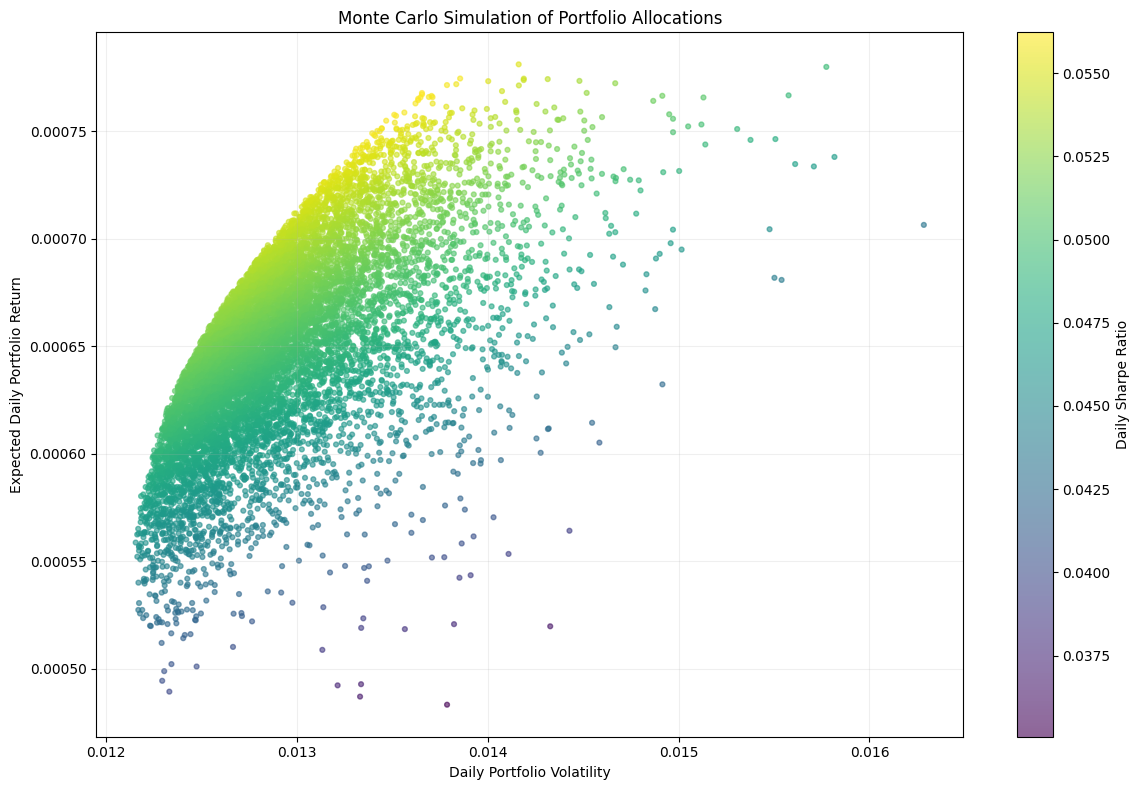

In [8]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    results["Volatility"],
    results["Return"],
    c=results["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.6,
    s=12
)
plt.colorbar(scatter, label="Daily Sharpe Ratio")
plt.xlabel("Daily Portfolio Volatility")
plt.ylabel("Expected Daily Portfolio Return")
plt.title("Monte Carlo Simulation of Portfolio Allocations")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Minimum-Volatility Portfolio

Among the sampled portfolios, the minimum-volatility portfolio is the one with the smallest estimated daily standard deviation. It is the least volatile candidate in this simulation, not necessarily the exact global minimum-variance portfolio.

In [9]:
min_vol_idx = results["Volatility"].idxmin()
min_vol = results.loc[min_vol_idx]
min_vol

,4447
Return,0.000559
Volatility,0.012154
Sharpe Ratio,0.045971


## Maximum-Sharpe Portfolio

Among the sampled portfolios, the maximum-Sharpe portfolio has the largest estimated Sharpe ratio under the zero risk-free-rate assumption. This is the best risk-adjusted candidate in the sampled set, not a guarantee of future outperformance.

In [10]:
max_sharpe_idx = results["Sharpe Ratio"].idxmax()
max_sharpe = results.loc[max_sharpe_idx]
max_sharpe

,4134
Return,0.000768
Volatility,0.013654
Sharpe Ratio,0.056227


## Highlight the Selected Portfolios

The plot below marks the minimum-volatility and maximum-Sharpe candidates within the same simulated portfolio universe.

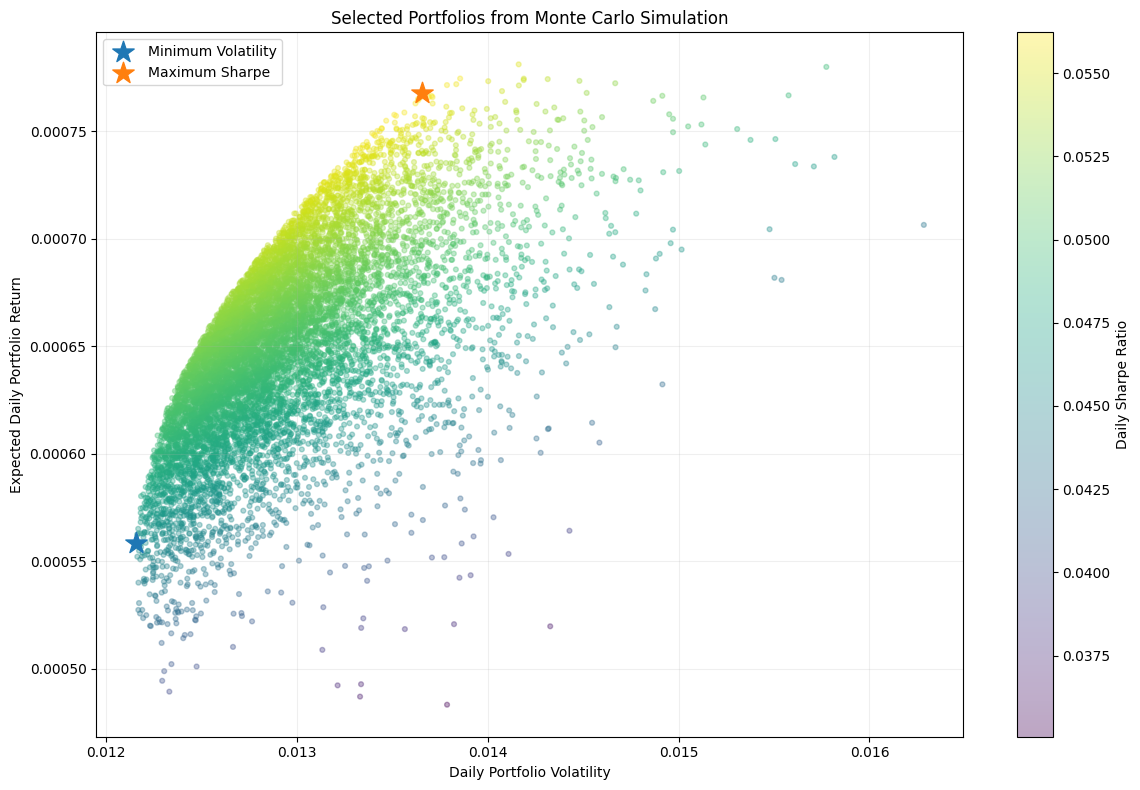

In [11]:
plt.figure(figsize=(12, 8))
scatter = plt.scatter(
    results["Volatility"],
    results["Return"],
    c=results["Sharpe Ratio"],
    cmap="viridis",
    alpha=0.35,
    s=12
)
plt.colorbar(scatter, label="Daily Sharpe Ratio")
plt.scatter(min_vol["Volatility"], min_vol["Return"], marker="*", s=260, label="Minimum Volatility")
plt.scatter(max_sharpe["Volatility"], max_sharpe["Return"], marker="*", s=260, label="Maximum Sharpe")
plt.xlabel("Daily Portfolio Volatility")
plt.ylabel("Expected Daily Portfolio Return")
plt.title("Selected Portfolios from Monte Carlo Simulation")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Asset Allocation

The weight vector associated with each selected portfolio tells us what fraction of capital is allocated to each stock. These are simulated allocations, so small changes in the random sample can change which portfolio is selected.

In [12]:
weights_df = pd.DataFrame(portfolio_weights, columns=stocks)
weights_df.head()

,RELIANCE.NS,TCS.NS,INFY.NS,HDFCBANK.NS,ICICIBANK.NS
0,0.270333,0.153294,0.299897,0.243581,0.032895
1,0.314582,0.245424,0.253461,0.041309,0.145224
2,0.115600,0.288927,0.200731,0.256503,0.138238
3,0.098588,0.240607,0.027687,0.359069,0.274049
4,0.201897,0.094419,0.258521,0.237860,0.207303


The table displays the first few simulated portfolios. Each row corresponds to a portfolio, each column corresponds to a stock, and each row sums to one.

### Weights for the Maximum-Sharpe Portfolio

In [13]:
weights_df.loc[max_sharpe_idx].rename("Weight").to_frame().assign(Weight_Percent=lambda df: 100 * df["Weight"])

,Weight,Weight_Percent
RELIANCE.NS,0.310293,31.029251
TCS.NS,0.007042,0.704162
INFY.NS,0.441665,44.166523
HDFCBANK.NS,0.004818,0.481846
ICICIBANK.NS,0.236182,23.618219


### Weights for the Minimum-Volatility Portfolio

In [14]:
weights_df.loc[min_vol_idx].rename("Weight").to_frame().assign(Weight_Percent=lambda df: 100 * df["Weight"])

,Weight,Weight_Percent
RELIANCE.NS,0.178172,17.817231
TCS.NS,0.377445,37.744458
INFY.NS,0.079515,7.951537
HDFCBANK.NS,0.298777,29.877695
ICICIBANK.NS,0.066091,6.609079


# Conclusions

- Monte Carlo simulation samples a large number of feasible portfolio allocations.
- Different allocations produce different combinations of expected return and volatility.
- The minimum-volatility and maximum-Sharpe portfolios are the best candidates **within the sampled set**.
- The random cloud approximates the feasible portfolio region; it does not by itself compute the exact Efficient Frontier.
- Numerical optimization, introduced in the next notebook, can solve the minimum-variance and maximum-Sharpe problems more systematically.

The estimates are based on historical daily returns and omit transaction costs, taxes, slippage, and other implementation constraints.

## Summary of Selected Simulated Portfolios

This table compares the equal-weight benchmark with the two selected portfolios. All return and volatility figures are daily estimates; Sharpe ratios use a zero daily risk-free rate.

In [15]:
equal_weights = np.full(len(stocks), 1 / len(stocks))
equal_return = float(np.dot(equal_weights, expected_returns.to_numpy()))
equal_vol = float(np.sqrt(equal_weights.T @ cov_matrix.to_numpy() @ equal_weights))
equal_sharpe = (equal_return - risk_free_rate_daily) / equal_vol

selected_portfolios = pd.DataFrame({
    "Return": [equal_return, min_vol["Return"], max_sharpe["Return"]],
    "Volatility": [equal_vol, min_vol["Volatility"], max_sharpe["Volatility"]],
    "Sharpe Ratio": [equal_sharpe, min_vol["Sharpe Ratio"], max_sharpe["Sharpe Ratio"]]
}, index=["Equal Weight", "Monte Carlo Minimum Volatility", "Monte Carlo Maximum Sharpe"])
selected_portfolios

,Return,Volatility,Sharpe Ratio
Equal Weight,0.000650,0.012516,0.051908
Monte Carlo Minimum Volatility,0.000559,0.012154,0.045971
Monte Carlo Maximum Sharpe,0.000768,0.013654,0.056227
